# Interpolación numérica

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    from scipy.interpolate import CubicSpline, interp1d
except ImportError:
    CubicSpline = None
    interp1d = None

# 1. INTERPOLACIÓN LINEAL ENTRE DOS PUNTOS

In [2]:
def interpolacion_lineal(x0, y0, x1, y1, x):
    """
    Interpolación lineal entre (x0, y0) y (x1, y1).
    """
    if x1 == x0:
        raise ValueError("x0 y x1 deben ser diferentes.")

    return y0 + (y1 - y0) * (x - x0) / (x1 - x0)


# Ejemplo
print("Interpolación lineal:")
print(interpolacion_lineal(1, 2, 3, 8, 2))

Interpolación lineal:
5.0


# 2. INTERPOLACIÓN LINEAL POR TRAMOS

In [3]:
def interpolacion_lineal_tramos(x_data, y_data, x):
    """
    Interpolación lineal por tramos.

    Para cada valor de x, identifica el intervalo correspondiente
    y utiliza los dos puntos vecinos.
    """
    x_data = np.asarray(x_data, dtype=float)
    y_data = np.asarray(y_data, dtype=float)

    if len(x_data) != len(y_data):
        raise ValueError("x_data e y_data deben tener la misma longitud.")

    if len(x_data) < 2:
        raise ValueError("Se necesitan al menos dos puntos.")

    if np.any(np.diff(x_data) <= 0):
        raise ValueError("Los valores de x deben estar ordenados y ser distintos.")

    x = np.asarray(x, dtype=float)

    if np.any(x < x_data[0]) or np.any(x > x_data[-1]):
        raise ValueError("El punto solicitado está fuera del intervalo de interpolación.")

    indices = np.searchsorted(x_data, x, side="right") - 1
    indices = np.clip(indices, 0, len(x_data) - 2)

    x0 = x_data[indices]
    x1 = x_data[indices + 1]
    y0 = y_data[indices]
    y1 = y_data[indices + 1]

    return y0 + (y1 - y0) * (x - x0) / (x1 - x0)

# 3. POLINOMIO DE LAGRANGE

In [4]:
def lagrange_interpolacion(x_data, y_data, x):
    """
    Evalúa el polinomio interpolante de Lagrange en x.
    Implementación directa con la fórmula matemática.
    """
    x_data = np.asarray(x_data, dtype=float)
    y_data = np.asarray(y_data, dtype=float)

    if len(x_data) != len(y_data):
        raise ValueError("x_data e y_data deben tener la misma longitud.")

    if len(np.unique(x_data)) != len(x_data):
        raise ValueError("Los nodos x deben ser distintos.")

    x_eval = np.asarray(x, dtype=float)
    resultado = np.zeros_like(x_eval, dtype=float)

    for i in range(len(x_data)):
        termino = np.ones_like(x_eval, dtype=float)

        for j in range(len(x_data)):
            if i != j:
                termino *= (x_eval - x_data[j]) / (x_data[i] - x_data[j])

        resultado += y_data[i] * termino

    return resultado


# Ejemplo
x_ej = np.array([0, 1, 2])
y_ej = np.array([1, 3, 2])

print("\nLagrange en x=1.5:")
print(lagrange_interpolacion(x_ej, y_ej, 1.5))


Lagrange en x=1.5:
2.875


# 4. TABLA DE DIFERENCIAS DIVIDIDAS

In [5]:
def tabla_diferencias_divididas(x_data, y_data):
    """
    Construye la tabla de diferencias divididas de Newton.

    La columna 0 contiene f(x_i).
    La columna 1 contiene diferencias divididas de primer orden.
    etc.
    """
    x_data = np.asarray(x_data, dtype=float)
    y_data = np.asarray(y_data, dtype=float)

    n = len(x_data)

    if len(y_data) != n:
        raise ValueError("x_data e y_data deben tener la misma longitud.")

    if len(np.unique(x_data)) != n:
        raise ValueError("Los nodos x deben ser distintos.")

    tabla = np.zeros((n, n), dtype=float)
    tabla[:, 0] = y_data

    for j in range(1, n):
        for i in range(n - j):
            numerador = tabla[i + 1, j - 1] - tabla[i, j - 1]
            denominador = x_data[i + j] - x_data[i]
            tabla[i, j] = numerador / denominador

    return tabla


def imprimir_tabla_newton(x_data, tabla):
    """
    Imprime una tabla sencilla de diferencias divididas.
    """
    n = len(x_data)

    print("\nTabla de diferencias divididas")
    print("-" * 70)

    for i in range(n):
        fila = [f"{x_data[i]:10.5f}"]

        for j in range(n - i):
            fila.append(f"{tabla[i, j]:14.7f}")

        print(" ".join(fila))

# 5. EVALUACIÓN DEL POLINOMIO DE NEWTON

In [6]:
def newton_interpolacion(x_data, y_data, x):
    """
    Evalúa el polinomio de Newton usando la tabla
    de diferencias divididas.
    """
    x_data = np.asarray(x_data, dtype=float)
    x_eval = np.asarray(x, dtype=float)

    tabla = tabla_diferencias_divididas(x_data, y_data)
    coeficientes = tabla[0, :]

    resultado = np.zeros_like(x_eval, dtype=float)

    for k in range(len(coeficientes)):
        termino = coeficientes[k]

        for j in range(k):
            termino *= (x_eval - x_data[j])

        resultado += termino

    return resultado

# 6. POLINOMIO DE NEWTON COMO TEXTO

In [7]:
def newton_coeficientes(x_data, y_data):
    """
    Devuelve los coeficientes de Newton:
        f[x0],
        f[x0,x1],
        f[x0,x1,x2], ...
    """
    tabla = tabla_diferencias_divididas(x_data, y_data)
    return tabla[0, :]

# 7. COMPARACIÓN LAGRANGE VS NEWTON

In [8]:
x = np.array([0.0, 1.0, 2.0, 3.0])
y = np.array([0.2, 1.1, 3.8, 8.9])

x_eval = 1.5

y_lagrange = lagrange_interpolacion(x, y, x_eval)
y_newton = newton_interpolacion(x, y, x_eval)

print("\nComparación Lagrange/Newton")
print(f"Lagrange: {y_lagrange:.10f}")
print(f"Newton:   {y_newton:.10f}")
print(f"Diferencia: {abs(y_lagrange - y_newton):.3e}")


Comparación Lagrange/Newton
Lagrange: 2.1875000000
Newton:   2.1875000000
Diferencia: 4.441e-16


# 8. FENÓMENO DE RUNGE

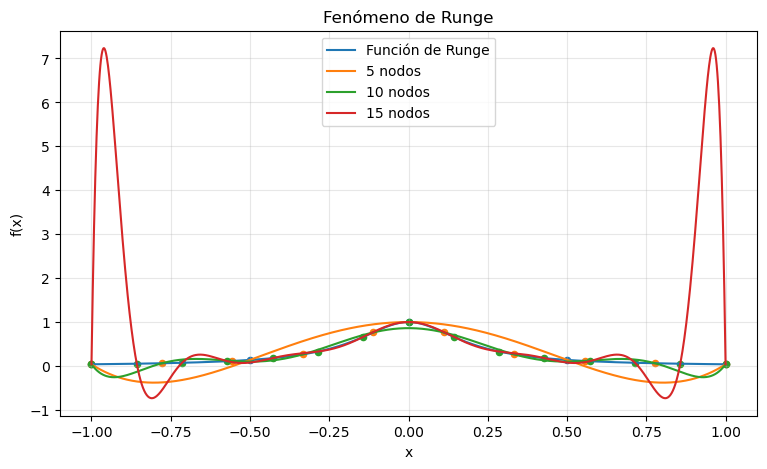

In [9]:
def runge(x):
    """
    Función clásica de Runge.
    """
    return 1 / (1 + 25 * x**2)


def graficar_runge():
    """
    Compara interpolaciones polinómicas de distintos grados
    con la función de Runge.
    """
    x_real = np.linspace(-1, 1, 1000)
    y_real = runge(x_real)

    cantidad_puntos = [5, 10, 15]

    plt.figure(figsize=(9, 5))
    plt.plot(x_real, y_real, label="Función de Runge")

    for n in cantidad_puntos:
        x_nodes = np.linspace(-1, 1, n)
        y_nodes = runge(x_nodes)

        y_interp = lagrange_interpolacion(
            x_nodes, y_nodes, x_real
        )

        plt.plot(
            x_real,
            y_interp,
            label=f"{n} nodos"
        )

        plt.scatter(
            x_nodes,
            y_nodes,
            s=20
        )

    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.title("Fenómeno de Runge")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


graficar_runge()

# 9. SPLINE CÚBICO

In [10]:
def spline_cubico(x_data, y_data):
    """
    Construye un spline cúbico natural usando SciPy.
    """
    if CubicSpline is None:
        raise ImportError(
            "Se requiere SciPy. Instale con: pip install scipy"
        )

    return CubicSpline(x_data, y_data)

# 10. COMPARACIÓN LINEAL VS SPLINE

In [11]:
def comparar_lineal_spline(x_data, y_data):
    """
    Grafica los datos junto con interpolación lineal y spline cúbico.
    """
    if interp1d is None or CubicSpline is None:
        raise ImportError("Se requiere SciPy.")

    x_data = np.asarray(x_data, dtype=float)
    y_data = np.asarray(y_data, dtype=float)

    x_new = np.linspace(
        x_data.min(),
        x_data.max(),
        500
    )

    lineal = interp1d(
        x_data,
        y_data,
        kind="linear"
    )

    spline = CubicSpline(
        x_data,
        y_data
    )

    plt.figure(figsize=(9, 5))

    plt.scatter(
        x_data,
        y_data,
        label="Datos"
    )

    plt.plot(
        x_new,
        lineal(x_new),
        label="Interpolación lineal"
    )

    plt.plot(
        x_new,
        spline(x_new),
        label="Spline cúbico"
    )

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Comparación de interpolaciones")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

# 11. DATOS EXPERIMENTALES

In [12]:
t = np.array([
    0.0,
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6
])

posicion = np.array([
    0.02,
    0.05,
    0.21,
    0.46,
    0.79,
    1.24,
    1.78
])

# 12. EVALUACIÓN EN UN PUNTO EXPERIMENTAL NO MEDIDO

In [13]:
t_consulta = 0.35

x_lineal = interpolacion_lineal_tramos(
    t,
    posicion,
    t_consulta
)

x_lagrange = lagrange_interpolacion(
    t,
    posicion,
    t_consulta
)

x_newton = newton_interpolacion(
    t,
    posicion,
    t_consulta
)

spline = spline_cubico(t, posicion)
x_spline = spline(t_consulta)

print("\nAplicación experimental")
print(f"t = {t_consulta} s")
print(f"Lineal:       {x_lineal:.8f} m")
print(f"Lagrange:     {x_lagrange:.8f} m")
print(f"Newton:       {x_newton:.8f} m")
print(f"Spline:       {x_spline:.8f} m")


Aplicación experimental
t = 0.35 s
Lineal:       0.62500000 m
Lagrange:     0.61294922 m
Newton:       0.61294922 m
Spline:       0.61220982 m


# 13. GRÁFICA DE LOS DATOS EXPERIMENTALES

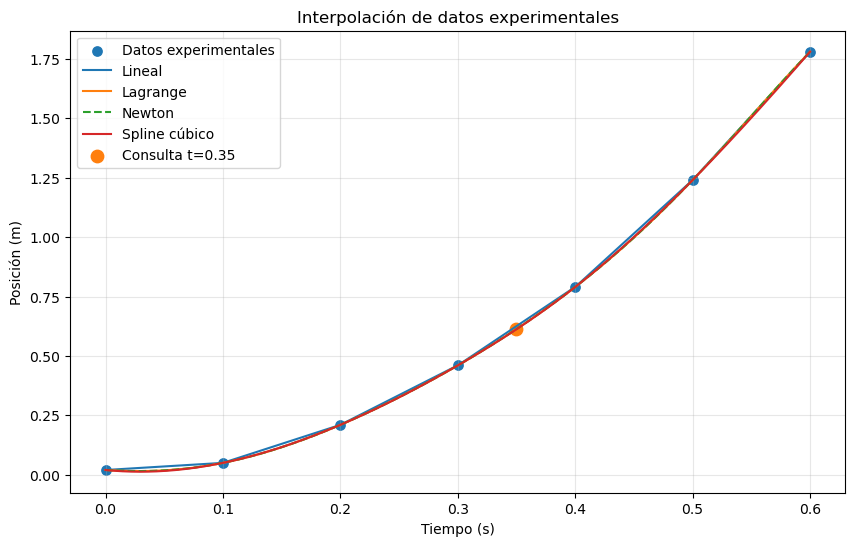

In [14]:
def graficar_datos_experimentales():
    """
    Muestra datos experimentales y los cuatro métodos.
    """
    x_new = np.linspace(t.min(), t.max(), 500)

    y_lineal = interpolacion_lineal_tramos(
        t,
        posicion,
        x_new
    )

    y_lagrange = lagrange_interpolacion(
        t,
        posicion,
        x_new
    )

    y_newton = newton_interpolacion(
        t,
        posicion,
        x_new
    )

    spline = CubicSpline(t, posicion)
    y_spline = spline(x_new)

    plt.figure(figsize=(10, 6))

    plt.scatter(
        t,
        posicion,
        s=45,
        label="Datos experimentales"
    )

    plt.plot(
        x_new,
        y_lineal,
        label="Lineal"
    )

    plt.plot(
        x_new,
        y_lagrange,
        label="Lagrange"
    )

    plt.plot(
        x_new,
        y_newton,
        linestyle="--",
        label="Newton"
    )

    plt.plot(
        x_new,
        y_spline,
        label="Spline cúbico"
    )

    plt.scatter(
        [t_consulta],
        [x_spline],
        s=80,
        label=f"Consulta t={t_consulta}"
    )

    plt.xlabel("Tiempo (s)")
    plt.ylabel("Posición (m)")
    plt.title("Interpolación de datos experimentales")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


graficar_datos_experimentales()


# 14. EJEMPLO CON TEMPERATURA

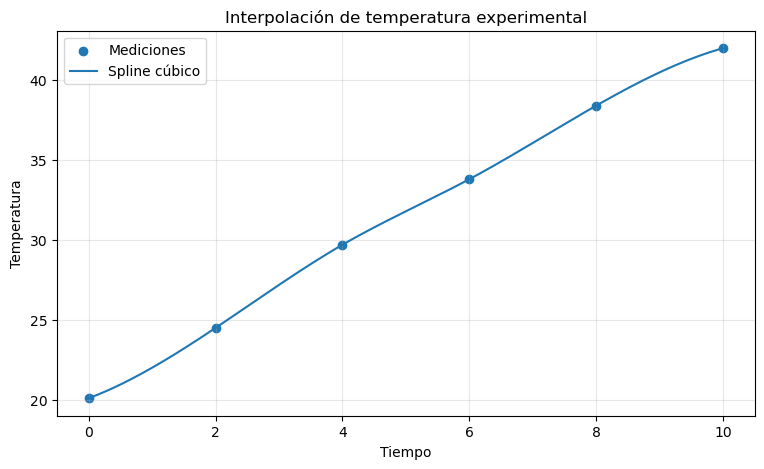

In [15]:
tiempo = np.array([
    0, 2, 4, 6, 8, 10
], dtype=float)

temperatura = np.array([
    20.1, 24.5, 29.7, 33.8, 38.4, 42.0
])

spline_temperatura = spline_cubico(
    tiempo,
    temperatura
)

t_nuevo = np.linspace(
    tiempo.min(),
    tiempo.max(),
    300
)

T_nuevo = spline_temperatura(t_nuevo)

plt.figure(figsize=(9, 5))
plt.scatter(
    tiempo,
    temperatura,
    label="Mediciones"
)
plt.plot(
    t_nuevo,
    T_nuevo,
    label="Spline cúbico"
)
plt.xlabel("Tiempo")
plt.ylabel("Temperatura")
plt.title("Interpolación de temperatura experimental")
plt.legend()
plt.grid(alpha=0.3)
plt.show()